
# IND320-1 26H Data til beslutning
**Student:** Lovisa Nguyen  
[GitHub](https://github.com/myelovis/reservoir_streamlit_app) · [Streamlit app](https://reservoir-app-datatodecision-v2026.streamlit.app/) · [Screencast](https://www.dropbox.com/scl/fi/hw6ba5bh9xf1y24ujr7t6/screencast_291026_quieter.mp4?rlkey=9yr6icgb86jr3q0nmf8k6oenu&st=cw72051u&dl=0)

---

# Tasks Summary

## 1. Accounts and Repository

- Reuse  GitHub account, repository and Streamlit app.
- Push changes to a **temporary branch**.

## 2. API and Spatial Data

- Explore [Open-Meteo](https://open-meteo.com/en/docs), including its data sections and generated Python examples.
- Download electricity and precipitation region shapefiles from [NVE Atlas](https://atlas.nve.no), matching Magasinstatistikk regions:
  - **East:** RS + RØ
  - **North:** RM + RN
- Randomly sample **1,000 locations per region**.
- Create a download function accepting a **region identifier and time interval**.
- Retrieve **hourly ERA5 historical reanalysis**, including precipitation and temperature.
- Run it for **NO3, full-year 2024**.

## 3. Jupyter Notebook Analyses

| Analysis | Requirements | Parameters |
|---|---|---|
| **1 Precipitation outliers / SPC** | Plot regional average precipitation. Use DCT high-pass residuals and robust annual statistics to identify outliers. Show boundaries and highlight outliers; do not plot residuals -SATV values . Return plot and outlier summaries. | DCT frequency cutoff; number of standard deviations |
| **2 Temperature anomalies / LOF** | Plot regional average temperature and highlight Local Outlier Factor anomalies. Return plot and anomaly summaries. | Outlier proportion, default **1%** |
| **3 STL decomposition** | Decompose Magasinstatistikk reservoir filling levels and plot the components. Return plot. | Seasonal smoother; trend smoother; robust mode |
| **4 Spectrogram** | Create a spectrogram of the same reservoir filling data. Return plot. | Window length; window overlap |

- Wrap each analysis in a function with sensible defaults and test it.
- Complete the required **work log and AI-use documentation**.


| Task | Required data |
|---|---|
| Sample 1,000 locations per region | **NVE region shapefiles** |
| Download hourly precipitation and temperature for NO3, 2024 | **ERA5 through Open-Meteo** |
| Precipitation outliers using DCT/SPC | **ERA5 precipitation** |
| Temperature anomalies using LOF | **ERA5 temperature** |
| STL decomposition of reservoir filling | **NVE Magasinstatistikk filling levels** |
| Spectrogram of reservoir filling | **The same NVE filling levels** |

## 4. Streamlit App — Under Development

- Extend the app from project part 2.
- Link meteorological data to the selected Magasinstatistikk region.
- Decide whether each page needs a local region selector.
- Add two pages using `st.tabs()`:
  - **Page A:** STL decomposition | Spectrogram
  - **Page B:** Outlier/SPC analysis | Anomaly/LOF analysis
- Include appropriate controls, plots and summary statistics.
- Arrange pages in a logical order.

## 5. Submission and Evaluation

- Prepare the **PDF, GitHub repository, Streamlit app and screencast**.
- Work will be reviewed by a fellow student and Liland or Osman.
- Address feedback and demonstrate fulfilment of the requirements.
- Final course assessment considers all four submission rounds together.

## Work log


| Task | Work performed | 
|---|---|
| Region boundaries | Obtained NVE electricity-area shapefiles for NO1–NO5. Kept all shapefile components together. |
| Spatial sampling | Generated and saved 1,000 reproducible random locations for each electricity area, NO1–NO5. | 
| ERA5 ingestion | Implemented `ingest_region(region_id, time_interval)` using Open-Meteo’s Historical Weather API with the ERA5 model. Retrieved hourly temperature and precipitation. | 
| NO3 download | Retrieved full-year 2024 data using 1,000 sampled locations, corresponding to 305 ERA5 grid cells. Saved 8,784 hourly regional averages. Shared grid cells were weighted by their sample counts when calculating regional averages. | 
| Precipitation outliers | Implemented DCT high-pass filtering and robust SPC limits, with configurable frequency cutoff and standard-deviation multiplier. Plotted precipitation, boundaries and highlighted outliers without plotting the filtered residuals. | 
| Temperature anomalies | Prepared a Local Outlier Factor function with a default outlier proportion of 1%, returning a plot and anomaly summaries. | 
| Reservoir data loading | Added the NVE Magasinstatistikk download cell and date conversion before creating the reservoir filling series. | 
| STL decomposition | Implemented and plotted STL decomposition of NO3’s weekly reservoir filling levels. Exposed seasonal smoother, trend smoother and robust mode as parameters. | P
| Spectrogram | Implemented and plotted a spectrogram using the same reservoir filling series, with configurable window length and overlap. | 
| Reproducibility | Used saved samples and cached weather downloads. Included basic assertions for output sizes and plot structure. | 


## Implementation 

### 0 Spatial Sampling & Data Ingestion

We are tying to obtain map boundaries that correspond to the religion of Norway (5 main regions).
The .shp file stores the shapes of those regions as geographic polygons. Ensure all associated shapefile components (.shp, .shx, .dbf, and .prj) are placed together in the working directory.

The intended order is download boundaries files → extract sample locations → fetch API weather for those.
Download files locate in geo-nve-atlas_data folders, using the era5_module to execute the code of sampling points from different region of NO1 to NO5.


In [2]:
#%pip install -r requirement.txt

#### Sample NO1 - NO5 Regions

In [3]:
from pathlib import Path
from era5_module import sample_points

folder = Path("samples")
folder.mkdir(exist_ok=True)

# randomly 1000 for each region
for region in ["NO1", "NO2", "NO3", "NO4", "NO5"]:
    points = sample_points(region, n=1000)
    points.to_csv(folder / f"{region}.csv", index=False)

#### Sample East, West, North

In [4]:
import requests
import geopandas as gpd
import pandas as pd

# Download NVE's five region polygons.
url = (
    "https://gis3.nve.no/map/rest/services/"
    "Mapservices/Administrasjon/MapServer/0/query"
)

response = requests.get(
    url,
    params={
        "where": "1=1",
        "outFields": "REGION,REGIONNAVN",
        "returnGeometry": "true",
        "outSR": 4326,
        "f": "geojson",
    },
    timeout=120,
)
response.raise_for_status()
payload = response.json()

if "error" in payload:
    raise ValueError(payload["error"])

regions = gpd.GeoDataFrame.from_features(
    payload["features"], crs="EPSG:4326"
)

# Verify source codes, then apply the assignment's grouping.
assert set(regions["REGION"]) == {"RS", "RØ", "RV", "RM", "RN"}

mapping = {
    "RS": "East", "RØ": "East",
    "RV": "West",
    "RM": "North", "RN": "North",
}

regions["region"] = regions["REGION"].map(mapping)
regions = regions.to_crs(3035).dissolve(by="region")

# Save the merged boundaries with their shapefile components.
boundary_folder = Path("boundaries")
boundary_folder.mkdir(exist_ok=True)
regions.reset_index().to_file(
    boundary_folder / "assignment_regions.shp",
    encoding="UTF-8",
)

# Sample uniformly by area, then convert to latitude/longitude.
counts = {}

for region, row in regions.iterrows():
    polygon = gpd.GeoSeries([row.geometry], crs=regions.crs)
    points = polygon.sample_points(size=1000, rng=42).explode(
        ignore_index=True
    )

    assert len(points) == 1000
    assert points.within(row.geometry).all()

    points = points.to_crs(4326)

    pd.DataFrame({
        "region": region,
        "point_id": range(1000),
        "latitude": points.y,
        "longitude": points.x,
    }).to_csv(folder / f"{region}.csv", index=False)

    counts[region] = len(points)

display(pd.Series(counts, name="Sampled locations"))

/home/tyyniuni/miniconda3/envs/nve-spark/lib/python3.11/site-packages/pyogrio/raw.py:733: RuntimeWarning: Normalized/laundered field name: 'REGION' to 'REGION_1'
  ogr_write(


East     1000
North    1000
West     1000
Name: Sampled locations, dtype: int64

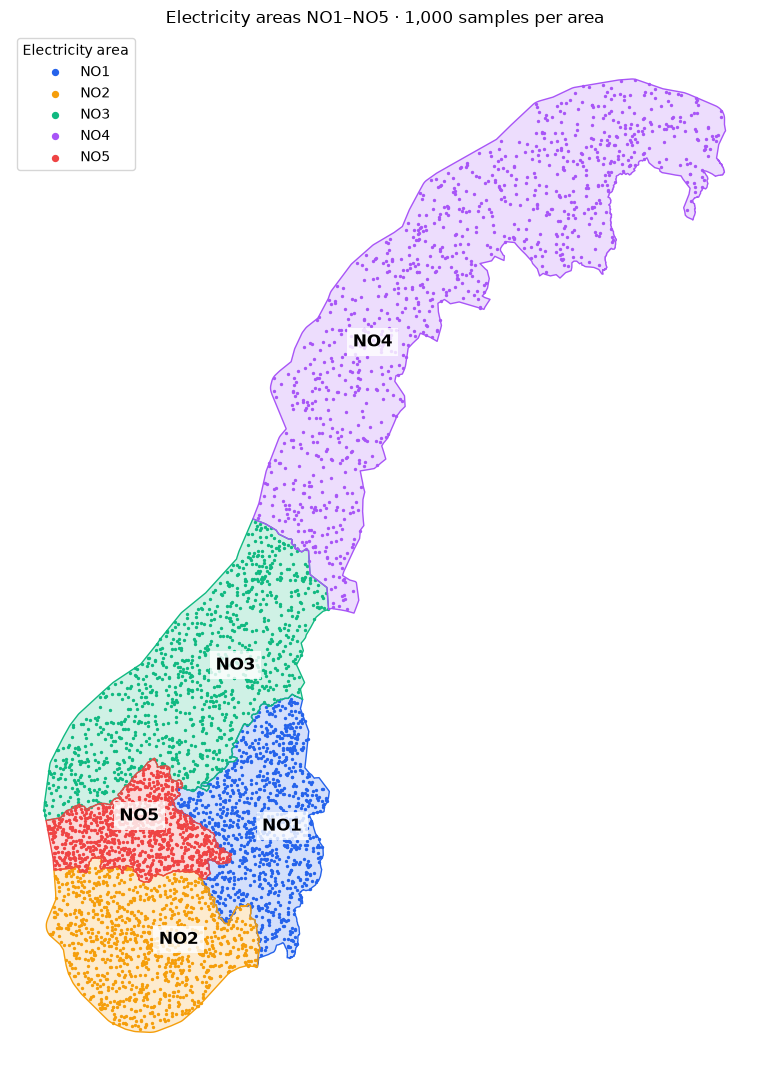

,Sampled points,Inside boundary,Valid geometry
Region,,,
NO1,1000,1000,True
NO2,1000,1000,True
NO3,1000,1000,True
NO4,1000,1000,True
NO5,1000,1000,True


In [5]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from era5_module import SHAPEFILE

boundaries = gpd.read_file(SHAPEFILE).to_crs(3035)
boundaries = boundaries.dissolve(by="region")

names = ["NO1", "NO2", "NO3", "NO4", "NO5"]
colours = ["#2563eb", "#f59e0b", "#10b981", "#a855f7", "#ef4444"]

fig, ax = plt.subplots(figsize=(8, 11))
checks = []

for name, colour in zip(names, colours):
    area = boundaries.loc[[name]]
    samples = pd.read_csv(folder / f"{name}.csv")

    points = gpd.GeoDataFrame(
        samples,
        geometry=gpd.points_from_xy(
            samples["longitude"], samples["latitude"]
        ),
        crs=4326,
    ).to_crs(boundaries.crs)

    inside = points.within(area.geometry.iloc[0])

    assert len(points) == 1000, f"{name}: expected 1,000 points."
    assert inside.all(), f"{name}: some points fall outside the boundary."

    area.plot(ax=ax, color=colour, alpha=0.2)
    area.boundary.plot(ax=ax, color=colour, linewidth=1)
    points.plot(ax=ax, color=colour, markersize=2, label=name)

    label = area.geometry.representative_point().iloc[0]
    ax.annotate(
        name, (label.x, label.y),
        fontsize=12, fontweight="bold",
        bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"),
    )

    checks.append({
        "Region": name,
        "Sampled points": len(points),
        "Inside boundary": int(inside.sum()),
        "Valid geometry": bool(area.geometry.is_valid.all()),
    })

ax.set_title("Electricity areas NO1–NO5 · 1,000 samples per area")
ax.set_axis_off()
ax.legend(title="Electricity area", markerscale=3)
plt.tight_layout()
plt.show()

display(pd.DataFrame(checks).set_index("Region"))

#### Sample NO3 2024 Weather

In [6]:
from era5_module import ingest_region

# run it for NO3
points, weather = ingest_region(
    region_id="NO3",
    time_interval=("2024-01-01", "2024-12-31"),
    n=1000,
)

print(f"Sampled locations: {len(points)}")
print(f"Hourly regional averages: {len(weather)}")
weather.head().T

1000 sample points use 305 ERA5 cells.
Sampled locations: 1000
Hourly regional averages: 8784


time,2024-01-01 00:00:00+00:00,2024-01-01 01:00:00+00:00,2024-01-01 02:00:00+00:00,2024-01-01 03:00:00+00:00,2024-01-01 04:00:00+00:00
temperature_2m,-3.4598,-3.5983,-3.5789,-3.6128,-3.5644
precipitation,0.0029,0.0027,0.0027,0.0027,0.0025


#### Local Database Solution

So we dont need to fetch the geo-points each time a new user visits the site. 
Use separate collections inside the same MongoDb Atlas

In [7]:
from getpass import getpass
from urllib.parse import quote_plus

import numpy as np
import pandas as pd
from pymongo import MongoClient, UpdateOne, ASCENDING

# ---------- Validate NO3 inputs ----------
region_id, year = "NO3", 2024
n_to_save = 1000  # Use 100 to save only the first 100 coordinates.
samples = points.head(n_to_save).copy()

assert len(points) == 1000
assert len(samples) == n_to_save
assert samples["point_id"].is_unique
assert samples["latitude"].between(-90, 90).all()
assert samples["longitude"].between(-180, 180).all()

columns = ["temperature_2m", "precipitation"]
hourly = weather[columns].copy()
hourly.index = pd.to_datetime(hourly.index, utc=True)
hourly = hourly.sort_index()

expected = pd.date_range(
    f"{year}-01-01", f"{year + 1}-01-01",
    freq="h", inclusive="left", tz="UTC",
)

assert hourly.index.equals(expected), "Expected all 8,784 hours of 2024."
assert np.isfinite(hourly.to_numpy()).all()
assert hourly["precipitation"].ge(0).all()

# ---------- Connect privately ----------
password = getpass("MongoDB password for lovisanguyen_db_user: ")

if not password:
    raise ValueError("Password cannot be empty.")

uri = (
    f"mongodb+srv://lovisanguyen_db_user:{quote_plus(password)}"
    "@cluster0.xvxeeyn.mongodb.net/"
    "?authSource=admin&appName=Cluster0&compressors=zlib"
)
del password

with MongoClient(
    uri, tz_aware=True, serverSelectionTimeoutMS=15000
) as client:
    client.admin.command("ping")
    print("Atlas connection successful.")

    db = client["nve"]
    sample_collection = db["era5_samples"]
    weather_collection = db["era5_hourly"]
    metadata = db["era5_datasets"]

    # Separate collections preserve the Part 2 transfer data.
    # Unique indexes make repeated uploads update existing records.
    sample_collection.create_index(
        [("region_id", ASCENDING), ("point_id", ASCENDING)],
        unique=True,
    )
    weather_collection.create_index(
        [
            ("region_id", ASCENDING),
            ("model", ASCENDING),
            ("time", ASCENDING),
        ],
        unique=True,
    )

    dataset_id = f"era5_{region_id}_{year}"
    metadata.update_one(
        {"_id": dataset_id},
        {"$set": {
            "region_id": region_id,
            "year": year,
            "model": "era5",
            "status": "uploading",
        }},
        upsert=True,
    )

    # ---------- Save sample coordinates ----------
    operations = []

    for point in samples.itertuples(index=False):
        key = {
            "region_id": region_id,
            "point_id": int(point.point_id),
        }
        operations.append(UpdateOne(
            key,
            {"$set": {
                **key,
                "latitude": float(point.latitude),
                "longitude": float(point.longitude),
                "source_sample_count": len(points),
            }},
            upsert=True,
        ))

    sample_collection.bulk_write(operations, ordered=False)

    # ---------- Save hourly regional weather averages ----------
    operations = []

    for timestamp, row in hourly.iterrows():
        key = {
            "region_id": region_id,
            "model": "era5",
            "time": timestamp.to_pydatetime(),
        }
        operations.append(UpdateOne(
            key,
            {"$set": {
                **key,
                "temperature_2m": float(row["temperature_2m"]),
                "precipitation": float(row["precipitation"]),
                "sample_count": len(points),
                "aggregation": "sample-weighted regional mean",
                "source": "Open-Meteo Historical Weather API",
            }},
            upsert=True,
        ))

    weather_collection.bulk_write(operations, ordered=False)

    # ---------- Read back and verify ----------
    saved_samples = pd.DataFrame(list(sample_collection.find(
        {
            "region_id": region_id,
            "point_id": {"$in": samples["point_id"].astype(int).tolist()},
        },
        {"_id": 0},
    ).sort("point_id", ASCENDING)))

    query = {
        "region_id": region_id,
        "model": "era5",
        "time": {
            "$gte": expected[0].to_pydatetime(),
            "$lt": pd.Timestamp(
                f"{year + 1}-01-01", tz="UTC"
            ).to_pydatetime(),
        },
    }

    saved_weather = pd.DataFrame(list(weather_collection.find(
        query,
        {
            "_id": 0, "time": 1,
            "temperature_2m": 1, "precipitation": 1,
        },
    ).sort("time", ASCENDING))).set_index("time")

    saved_weather.index = pd.to_datetime(saved_weather.index, utc=True)

    ordered_samples = samples.sort_values("point_id")
    assert len(saved_samples) == n_to_save
    np.testing.assert_allclose(
        saved_samples[["latitude", "longitude"]].to_numpy(),
        ordered_samples[["latitude", "longitude"]].to_numpy(),
    )
    assert saved_weather.index.equals(expected)
    np.testing.assert_allclose(
        saved_weather[columns].to_numpy(),
        hourly[columns].to_numpy(),
    )

    # Mark complete only after successful verification.
    metadata.update_one(
        {"_id": dataset_id},
        {"$set": {
            "status": "complete",
            "hours": len(saved_weather),
            "source_sample_count": len(points),
            "saved_coordinate_count": len(saved_samples),
            "updated_at": pd.Timestamp.now(tz="UTC").to_pydatetime(),
        }},
    )

print(f"Verified: {len(saved_samples):,} coordinates in nve.era5_samples.")
print(f"Verified: {len(saved_weather):,} hourly averages in nve.era5_hourly.")
display(saved_samples.head())
display(saved_weather.head().T)

MongoDB password for lovisanguyen_db_user:  ········


Atlas connection successful.
Verified: 1,000 coordinates in nve.era5_samples.
Verified: 8,784 hourly averages in nve.era5_hourly.


,point_id,region_id,latitude,longitude,source_sample_count
0,0,NO3,62.930168,10.899322,1000
1,1,NO3,64.091800,11.752027,1000
2,2,NO3,64.500652,10.823836,1000
3,3,NO3,64.668500,9.674575,1000
4,4,NO3,61.961864,7.902486,1000


time,2024-01-01 00:00:00+00:00,2024-01-01 01:00:00+00:00,2024-01-01 02:00:00+00:00,2024-01-01 03:00:00+00:00,2024-01-01 04:00:00+00:00
precipitation,0.0029,0.0027,0.0027,0.0027,0.0025
temperature_2m,-3.4598,-3.5983,-3.5789,-3.6128,-3.5644


Verified: all 1,000 download locations are inside NO3.


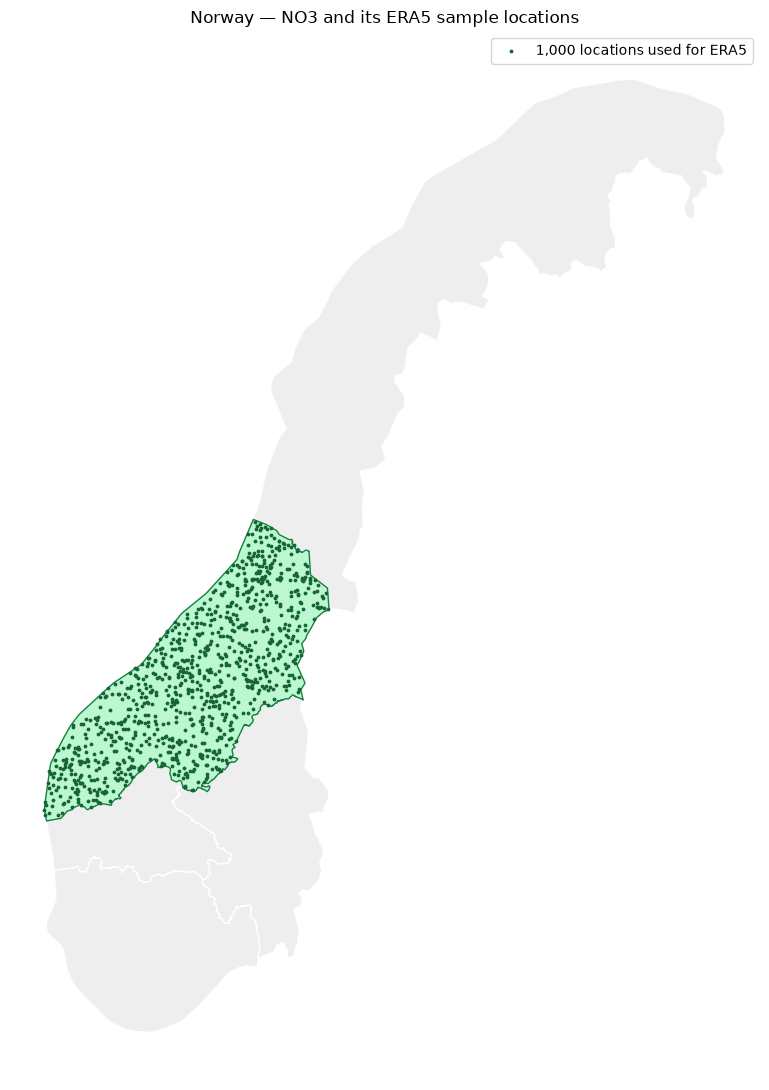

In [9]:
import geopandas as gpd
import matplotlib.pyplot as plt
from era5_module import SHAPEFILE

# Load all electricity boundaries and select NO3.
norway_electricity = gpd.read_file(SHAPEFILE).to_crs(3035)

no3_boundary = norway_electricity.loc[
    norway_electricity["region"] == "NO3"
].dissolve()

if no3_boundary.empty:
    raise ValueError("NO3 was not found in the electricity shapefile.")

# Use the actual coordinates returned by ingest_region("NO3", ...).
download_points = gpd.GeoDataFrame(
    points.copy(),
    geometry=gpd.points_from_xy(points.longitude, points.latitude),
    crs=4326,
).to_crs(norway_electricity.crs)

assert len(download_points) == 1000, "Expected 1,000 sample locations."
assert download_points.within(no3_boundary.geometry.iloc[0]).all(), (
    "Some points are outside NO3. Check that 'points' comes from the NO3 download."
)

print("Verified: all 1,000 download locations are inside NO3.")

# Show Norway with only NO3 and its points highlighted.
fig, ax = plt.subplots(figsize=(8, 11))

norway_electricity.plot(
    ax=ax, color="#eeeeee", edgecolor="white",
)
no3_boundary.plot(
    ax=ax, color="#bbf7d0", edgecolor="#15803d",
)
download_points.plot(
    ax=ax, color="#166534", markersize=3,
    label="1,000 locations used for ERA5",
)

ax.set_title("Norway — NO3 and its ERA5 sample locations")
ax.set_axis_off()
ax.legend()
plt.tight_layout()
plt.show()

### 1 Precipitation Outliers

1000 sample points use 305 ERA5 cells.


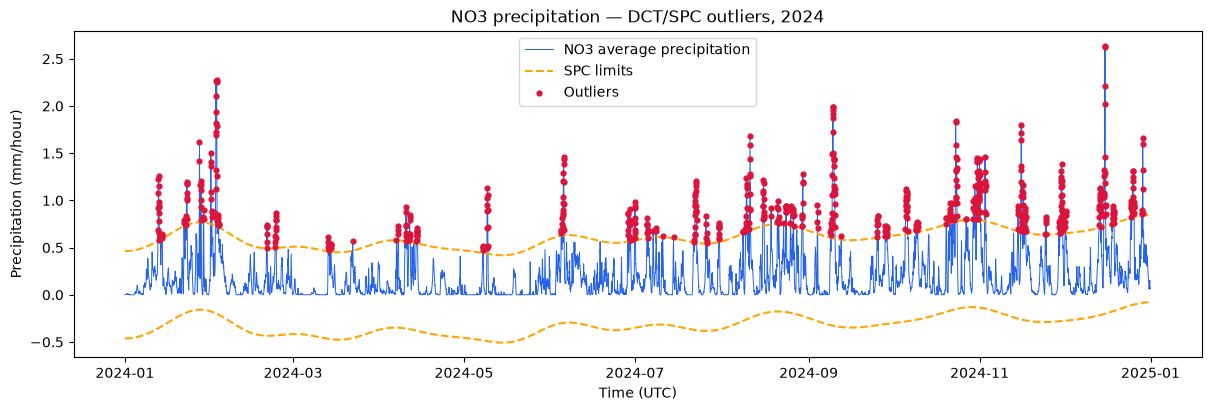

hours              8784.000000
outlier_hours       637.000000
outlier_percent       7.250000
robust_sigma          0.154304
dtype: float64

time,2024-01-12 20:00:00+00:00,2024-01-12 21:00:00+00:00,2024-01-12 22:00:00+00:00,2024-01-12 23:00:00+00:00,2024-01-13 00:00:00+00:00
precipitation,0.6847,0.9212,1.08,1.2228,1.2618
lower_limit,-0.3558,-0.355108,-0.354415,-0.353721,-0.353024
upper_limit,0.570021,0.570713,0.571406,0.572101,0.572797
outlier,True,True,True,True,True


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import dct, idct
from scipy.stats import median_abs_deviation
from era5_module import ingest_region


def precipitation_spc(weather, cutoff_days=30, n_sigma=3):
    """Return the precipitation plot, outliers and summary."""
    y = weather["precipitation"].copy()
    y.index = pd.to_datetime(y.index, utc=True)
    y = y.sort_index()

    if len(y) < 3 or not np.isfinite(y.to_numpy()).all():
        raise ValueError("Provide at least three finite precipitation values.")
    if not (y.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all():
        raise ValueError("Data must contain consecutive hourly observations.")
    if cutoff_days <= 1 / 12 or n_sigma <= 0:
        raise ValueError("Use cutoff_days > 1/12 and n_sigma > 0.")

    # DCT high-pass filtering.
    coefficients = dct(y.to_numpy(), norm="ortho")
    frequency = np.arange(len(y)) / (2 * len(y))
    coefficients[frequency < 1 / (24 * cutoff_days)] = 0

    residual = idct(coefficients, norm="ortho")
    baseline = y.to_numpy() - residual

    # Robust statistics from the complete input year.
    centre = np.median(residual)
    sigma = median_abs_deviation(residual, scale="normal")

    if sigma <= np.finfo(float).eps:
        raise ValueError("Residual variability is too small for SPC limits.")

    # Translate residual limits back to the precipitation scale.
    lower = baseline + centre - n_sigma * sigma
    upper = baseline + centre + n_sigma * sigma
    flagged = (y.to_numpy() < lower) | (y.to_numpy() > upper)

    results = pd.DataFrame({
        "precipitation": y,
        "lower_limit": lower,
        "upper_limit": upper,
        "outlier": flagged,
    })
    outliers = results.loc[flagged]

    # Plot precipitation and limits only—not filtered residuals/SATV.
    fig, ax = plt.subplots(figsize=(12, 4), constrained_layout=True)
    ax.plot(
        y.index, y, color="#2563eb", linewidth=0.7,
        label="NO3 average precipitation",
    )
    ax.plot(y.index, lower, "--", color="orange", label="SPC limits")
    ax.plot(y.index, upper, "--", color="orange")
    ax.scatter(
        y.index[flagged], y.iloc[flagged],
        color="crimson", s=12, label="Outliers", zorder=3,
    )
    ax.set(
        title="NO3 precipitation — DCT/SPC outliers, 2024",
        xlabel="Time (UTC)",
        ylabel="Precipitation (mm/hour)",
    )
    ax.legend()

    summary = {
        "hours": len(y),
        "outlier_hours": int(flagged.sum()),
        "outlier_percent": round(100 * flagged.mean(), 2),
        "robust_sigma": float(sigma),
    }
    return fig, outliers, summary


# Load NO3 ERA5 data; completed downloads are reused.
points_no3, weather_no3 = ingest_region(
    region_id="NO3",
    time_interval=("2024-01-01", "2024-12-31"),
    n=1000,
)

# Validate all 8,784 hourly timestamps in leap-year 2024.
expected = pd.date_range(
    "2024-01-01", "2025-01-01",
    freq="h", inclusive="left", tz="UTC",
)
actual = pd.DatetimeIndex(pd.to_datetime(weather_no3.index, utc=True))

assert len(points_no3) == 1000
assert actual.equals(expected), "Expected all 8,784 hours of 2024."

# Run the analysis and check the returned summary.
fig, outliers, summary = precipitation_spc(
    weather_no3, cutoff_days=30, n_sigma=3,
)

assert summary["outlier_hours"] == len(outliers)
assert outliers["outlier"].all()

plt.show()
display(pd.Series(summary))
display(outliers.head().T)

### 2 Temperature anomalies - LOF

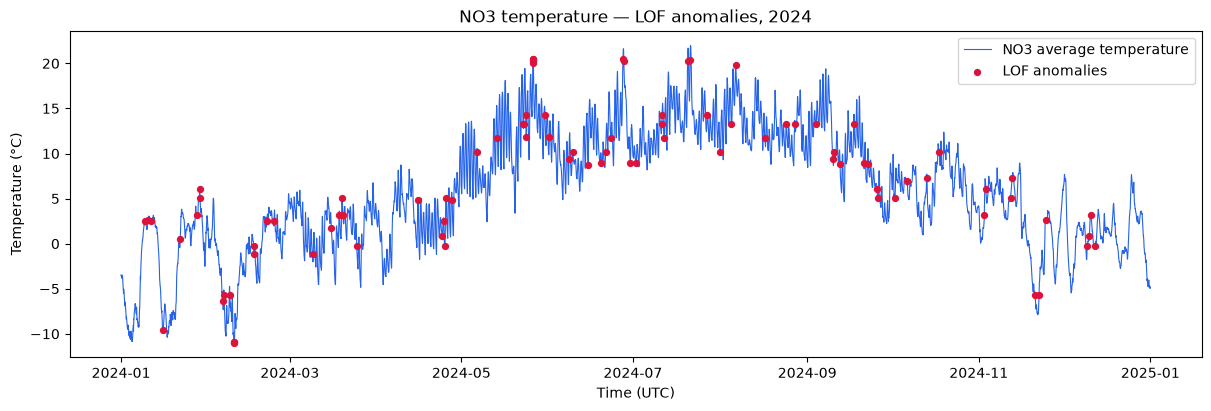

hours              8784.0
anomaly_hours        88.0
anomaly_percent       1.0
dtype: float64

time,2024-01-09 15:00:00+00:00,2024-01-10 14:00:00+00:00,2024-01-11 13:00:00+00:00,2024-01-15 18:00:00+00:00,2024-01-22 01:00:00+00:00
temperature,2.5396,2.5919,2.5385,-9.5623,0.5674
lof_score,1.197519,1.248242,1.189547,1.190667,1.212259
anomaly,True,True,True,True,True


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import LocalOutlierFactor


def temperature_lof(weather, proportion=0.01, neighbours=20):
    """Return the temperature plot, anomalies and summary."""
    y = weather["temperature_2m"].copy()
    y.index = pd.to_datetime(y.index, utc=True)
    y = y.sort_index()

    if len(y) < 3 or not np.isfinite(y.to_numpy()).all():
        raise ValueError("Provide at least three finite temperature values.")
    if not (y.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all():
        raise ValueError("Data must contain consecutive hourly observations.")
    if not 0 < proportion <= 0.5:
        raise ValueError("proportion must be greater than 0 and at most 0.5.")
    if not isinstance(neighbours, int) or not 1 <= neighbours < len(y):
        raise ValueError("neighbours must be an integer between 1 and len(data) - 1.")

    # Identify unusual values using temperature-space neighbours.
    model = LocalOutlierFactor(
        n_neighbors=neighbours,
        contamination=proportion,
    )
    flagged = model.fit_predict(y.to_numpy().reshape(-1, 1)) == -1

    results = pd.DataFrame({
        "temperature": y,
        "lof_score": -model.negative_outlier_factor_,
        "anomaly": flagged,
    })
    anomalies = results.loc[flagged]

    fig, ax = plt.subplots(figsize=(12, 4), constrained_layout=True)
    ax.plot(
        y.index, y, color="#2563eb", linewidth=0.8,
        label="NO3 average temperature",
    )
    ax.scatter(
        y.index[flagged], y.iloc[flagged],
        color="crimson", s=18, label="LOF anomalies", zorder=3,
    )
    ax.set(
        title="NO3 temperature — LOF anomalies, 2024",
        xlabel="Time (UTC)",
        ylabel="Temperature (°C)",
    )
    ax.legend()

    summary = {
        "hours": len(y),
        "anomaly_hours": int(flagged.sum()),
        "anomaly_percent": round(100 * flagged.mean(), 2),
    }
    return fig, anomalies, summary


# Validate the NO3 data loaded in the previous block.
expected = pd.date_range(
    "2024-01-01", "2025-01-01",
    freq="h", inclusive="left", tz="UTC",
)
actual = pd.DatetimeIndex(pd.to_datetime(weather_no3.index, utc=True))

assert actual.equals(expected), "Expected all 8,784 hours of 2024."

# Run LOF with the required default outlier proportion of 1%.
fig, anomalies, summary = temperature_lof(
    weather_no3,
    proportion=0.01,
    neighbours=20,
)

assert summary["hours"] == 8784
assert summary["anomaly_hours"] == len(anomalies)
assert anomalies["anomaly"].all()
assert np.isfinite(anomalies["lof_score"]).all()

plt.show()
display(pd.Series(summary))
display(anomalies.head().T)

### 3 Seasonal-Trend decomposition using LOESS (STL)

In [12]:
import requests
import pandas as pd

url = (
    "https://biapi.nve.no/magasinstatistikk/"
    "api/Magasinstatistikk/HentOffentligData"
)
response = requests.get(url, timeout=120)
response.raise_for_status()

data = pd.DataFrame(response.json())
data["dato_Id"] = pd.to_datetime(data["dato_Id"])

In [13]:
from statsmodels.tsa.seasonal import STL

def plot_stl(filling, seasonal=13, trend=89, robust=True):
    y = filling.sort_index().astype(float)

    if len(y) < 104 or not np.isfinite(y).all():
        raise ValueError("Provide at least two years of valid weekly data.")
    if not (y.index.to_series().diff().dropna() == pd.Timedelta(days=7)).all():
        raise ValueError("Data must contain consecutive weekly observations.")

    result = STL(
        y, period=52, seasonal=seasonal,
        trend=trend, robust=robust,
    ).fit()

    with plt.style.context("seaborn-v0_8-whitegrid"):
        fig, axes = plt.subplots(
            4, 1, figsize=(13, 9), sharex=True,
            gridspec_kw={"height_ratios": [2, 1, 1, 1]},
            constrained_layout=True,
        )

        # Observed filling and estimated trend
        axes[0].plot(y.index, y, color="#2563eb", lw=1.5, label="Filling")
        axes[0].fill_between(y.index, y, color="#2563eb", alpha=0.1)
        axes[0].plot(y.index, result.trend, color="#f59e0b",
                     lw=2, label="Trend")
        axes[0].set_ylim(0, 100)
        axes[0].legend(loc="upper right", frameon=False)

        axes[1].plot(y.index, result.trend, color="#f59e0b", lw=2)

        axes[2].plot(y.index, result.seasonal, color="#0d9488", lw=1.5)
        axes[2].axhline(0, color="gray", lw=0.7)

        colours = np.where(result.resid >= 0, "#2563eb", "#e11d48")
        axes[3].bar(y.index, result.resid, width=5, color=colours, alpha=0.8)
        axes[3].axhline(0, color="gray", lw=0.7)

        labels = ["Filling (%)", "Trend (%)", "Seasonal (pp)", "Residual (pp)"]
        for ax, label in zip(axes, labels):
            ax.set_ylabel(label)
            ax.spines[["top", "right"]].set_visible(False)
            ax.grid(axis="x", visible=False)

        axes[-1].set_xlabel("Year")
        fig.suptitle(
            f"NO3 reservoir filling · {y.index.min():%Y}–{y.index.max():%Y}\n"
            "Seasonal–Trend decomposition using LOESS",
            fontsize=16, fontweight="bold",
        )

    return fig

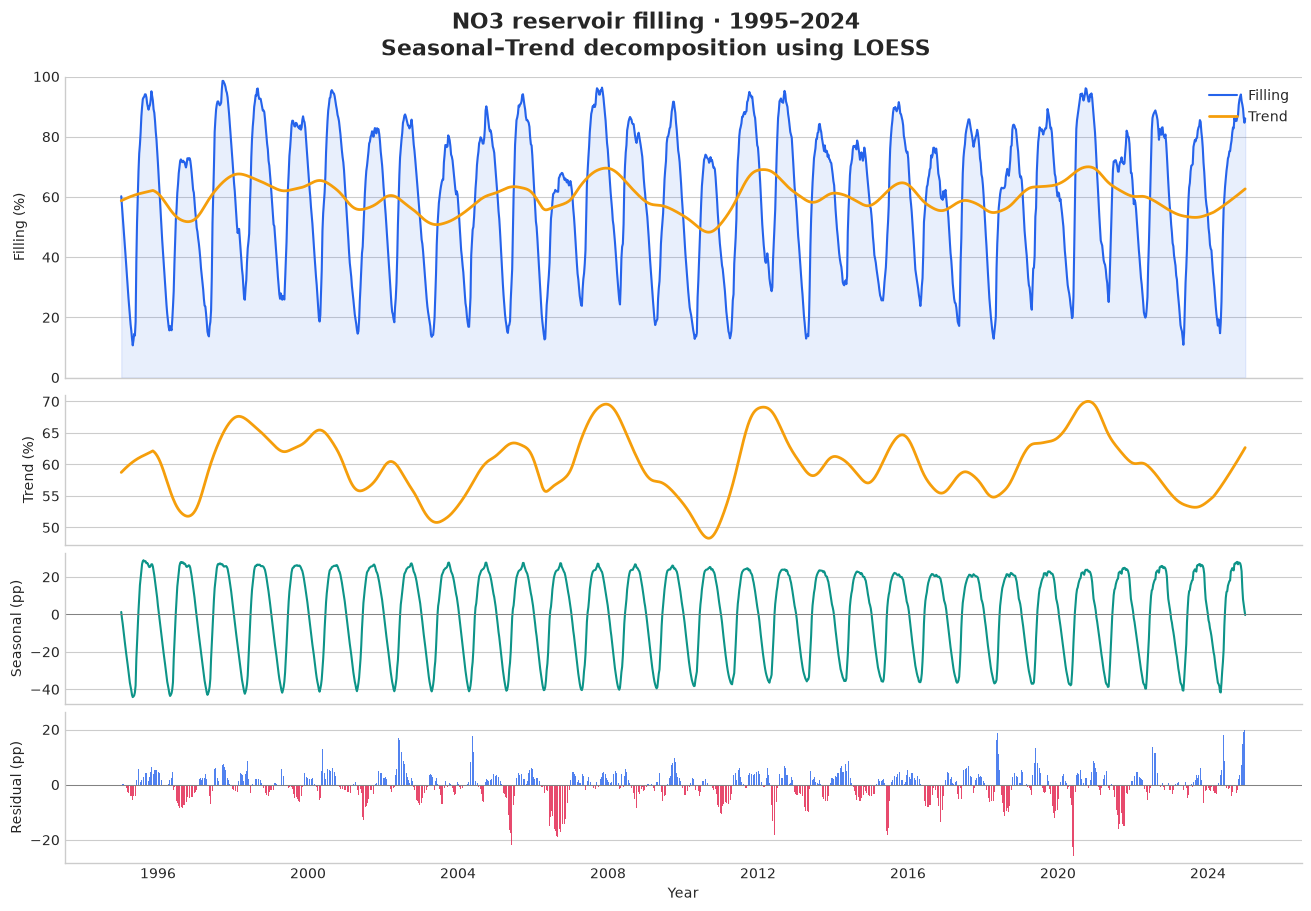

In [14]:
filling = (
    data.loc[(data["omrType"] == "EL") & (data["omrnr"] == 3)]
    .set_index("dato_Id")["fyllingsgrad"]
    .sort_index()
    .loc[:"2024"]
    .mul(100)
)

fig = plot_stl(filling)
assert len(fig.axes) == 4
plt.show()

### 4 Spectrogram

In [15]:
def plot_spectrogram(filling, window_length=104, window_overlap=78):
    """Return a spectrogram of weekly reservoir filling levels."""
    y = filling.sort_index().astype(float)

    if not isinstance(y.index, pd.DatetimeIndex):
        raise ValueError("Use a DatetimeIndex.")
    if not np.isfinite(y).all():
        raise ValueError("Resolve missing or infinite values first.")
    if not (y.index.to_series().diff().dropna() == pd.Timedelta(days=7)).all():
        raise ValueError("Data must contain consecutive weekly observations.")
    if not 0 <= window_overlap < window_length:
        raise ValueError("Overlap must be between 0 and window_length - 1.")
    if window_length < 4 or len(y) < 2 * window_length - window_overlap:
        raise ValueError("Provide enough data for at least two windows.")

    frequency, time, power = spectrogram(
        y.to_numpy(),
        fs=52,                     # approximately 52 observations/year
        window="hann",
        nperseg=window_length,
        noverlap=window_overlap,
        detrend="linear",
        scaling="density",
    )

    # Convert window centres to dates; exclude the zero-frequency component.
    dates = y.index[0] + pd.to_timedelta(time * 52 * 7, unit="D")
    power_db = 10 * np.log10(np.maximum(power[1:], 1e-12))

    fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
    image = ax.pcolormesh(
        dates, frequency[1:], power_db,
        shading="auto", cmap="magma",
    )
    ax.axhline(1, color="cyan", linestyle="--", label="Annual cycle")
    ax.set(
        title="Reservoir filling — spectrogram",
        xlabel="Window centre",
        ylabel="Frequency (cycles/year)",
        ylim=(0, 6),
    )
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.legend(loc="upper right")
    fig.colorbar(image, ax=ax, label="PSD (dB re 1 percentage-point² / cycle/year)")
    return fig

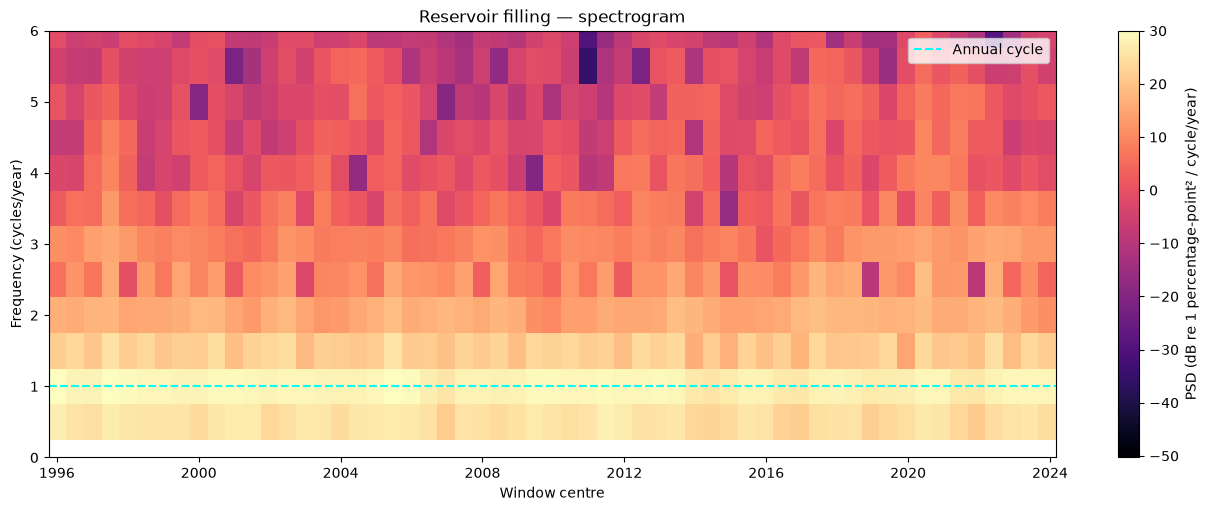

In [16]:
from scipy.signal import spectrogram
import matplotlib.dates as mdates

fig = plot_spectrogram(
    filling,
    window_length=104,
    window_overlap=78,
)

assert len(fig.axes) == 2  # Spectrogram and colour bar
plt.show()

## AI Usage

### Key Metrics & Breakdown

| Task Category | Total Queries | Share (%) | Primary Tools / Libraries |
| :--- | :---: | :---: | :--- |
| **Spatial Sampling & Data Ingestion** | 5 | 31.25% | `geopandas`, `shapely`, `cdsapi`, `xarray` |
| **Package Dependency & Environment Resolution** | 5 | 31.25% | `pip`, PyPI, `pyogrio`, GDAL |
| **Code Refactoring & Educational Explanations** | 2 | 12.50% | Python core, `random` |
| **Data Visualization & Signal Processing** | 4 | 25.00% | `scipy.signal`, `matplotlib.dates` |

---

### Issues Encountered & Resolutions

| Issue Description | Root Cause | Resolution Implemented |
| :--- | :--- | :--- |
| `ModuleNotFoundError: No module named 'geopandas'`[cite: 3] | Uninstalled spatial library[cite: 3] | Pinned and installed `geopandas==1.0.1` |
| `ModuleNotFoundError: No module named 'cdsapi'`[cite: 5] | Missing CDS API package[cite: 5] | Added `cdsapi` to requirements file |
| `DataSourceError: Unable to open *.shx` | Incomplete shapefile set | Set `os.environ["SHAPE_RESTORE_SHX"] = "YES"` |
| `ModuleNotFoundError: No module named 'fast_era5'` | Missing local module file | Created modular `fast_era5.py` helper script |
| `NameError: name 'spectrogram' is not defined`[cite: 6] | Missing module import[cite: 6] | Added `from scipy.signal import spectrogram` |
| `NameError: name 'mdates' is not defined`[cite: 7] | Missing module import[cite: 7] | Added `import matplotlib.dates as mdates` |

## AI Usage

| Area | AI contribution |
|---|---|
| Data sources | Explained the distinction between NVE region boundaries, NVE reservoir filling data, and ERA5 weather data from Open-Meteo. |
| Spatial sampling | Helped implement reproducible sampling of 1,000 locations per region, coordinate conversion, CSV export, and containment checks. |
| Regional grouping | Provided code to merge RS + RØ into East, RM + RN into North, and retain RV as West, following the assignment’s **grouping**. |
| Map visualisation | Helped plot all electricity areas and highlight NO3 with its sample locations. Distinguished separately generated samples from those actually used for weather downloads. |
| ERA5 ingestion | Helped develop `ingest_region(region_id, time_interval)` to retrieve hourly ERA5 temperature and precipitation, reuse shared grid cells, cache downloads, and calculate sample-weighted regional averages. |
| Precipitation SPC | Provided DCT high-pass filtering and robust SPC analysis with configurable cutoff and standard-deviation multiplier. Filtered residuals are used internally, not plotted. |
| Temperature LOF | Provided anomaly detection with a default outlier proportion of 1%, returning a plot, anomaly table, and summary. Updated the code to use `weather_no3` explicitly. |
| STL decomposition | Helped implement decomposition of weekly reservoir filling levels with configurable seasonal smoother, trend smoother, and robust mode. |
| Spectrogram | Helped implement a spectrogram of the same reservoir filling series with configurable window length and overlap. |
| Troubleshooting | Assisted with missing shapefile components, missing Python modules, ambiguous index/column names, and plotting errors. |
| Review and documentation | Reviewed notebook code and saved outputs, identified missing sections, and helped organise the work log. |


In [19]:
# publishes NVE reservoir observations

from publish_atlas import publish_reservoirs

print("Reservoir records published:", publish_reservoirs(uri))

2026-10-29 13:38:51.642 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


Reservoir records published: 14940
